# Research relationship plots

This notebook compares traffic-camera violations and speed-camera records over the years. The aim is to see whether the presence of flock cameras have any impact on speed and red light violations.

In [1]:
import json

import matplotlib.pyplot as plt
import polars as pl

## Traffic Violations

Compare the monthly average reported violations per exported record for red-light and speed cameras. This is not a Flock-camera outcome measure.

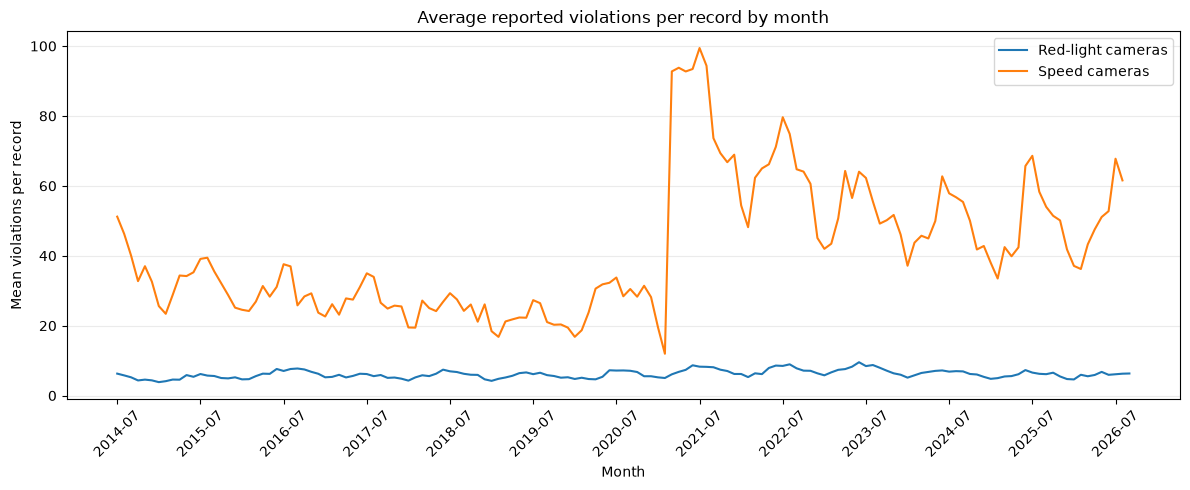

Red-light lowest: ('2015-01', 3.83841059602649) highest: ('2023-06', 9.534458509142054)
Speed-camera lowest: ('2021-02', 11.966153846153846) highest: ('2021-07', 99.42753623188406)


In [2]:
red_light = pl.read_csv("../red_light_100000.csv", schema_overrides={"VIOLATIONS": pl.String}).select(
    pl.col("VIOLATION DATE")
    .str.strptime(pl.Date, "%m/%d/%Y", strict=False)
    .dt.strftime("%Y-%m")
    .alias("month"),
    pl.col("VIOLATIONS").str.replace_all(",", "").cast(pl.Float64, strict=False).alias("violations"),
).drop_nulls().group_by("month").agg(pl.col("violations").mean().alias("mean_violations")).sort("month")

speed_camera = pl.read_csv("../speed_violations_150000.csv", schema_overrides={"VIOLATIONS": pl.String}).select(
    pl.col("VIOLATION DATE")
    .str.strptime(pl.Date, "%m/%d/%Y", strict=False)
    .dt.strftime("%Y-%m")
    .alias("month"),
    pl.col("VIOLATIONS").str.replace_all(",", "").cast(pl.Float64, strict=False).alias("violations"),
).drop_nulls().group_by("month").agg(pl.col("violations").mean().alias("mean_violations")).sort("month")

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(red_light["month"], red_light["mean_violations"], label="Red-light cameras")
ax.plot(speed_camera["month"], speed_camera["mean_violations"], label="Speed cameras")
ax.set(title="Average reported violations per record by month", xlabel="Month", ylabel="Mean violations per record")
ax.tick_params(axis="x", labelrotation=45)
ax.set_xticks(ax.get_xticks()[::12])
ax.grid(axis="y", alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

for label, monthly_data in [("Red-light", red_light), ("Speed-camera", speed_camera)]:
    print(label, "lowest:", monthly_data.sort("mean_violations").row(0), "highest:", monthly_data.sort("mean_violations", descending=True).row(0))

## Obversation

The speed-camera line is usually higher and changes more sharply from month to month than the red-light-camera line. In the data shown, the speed-camera average ranges from about 12 violations per record in February 2021 to about 99 in July 2021. The red-light-camera average is steadier, ranging from about 3.8 in January 2015 to about 9.5 in June 2023. Some ups and downs are expected because traffic and enforcement can change with the season. However, the July 2021 speed-camera peak surprised me. The average also appears higher from 2021 onward than it was through 2020. A change that large might reflect a real change in traffic or enforcement, but it could also be caused by changes in the records included in the dataset, camera coverage, or how violations were reported. I would not assume the increase is a direct change in how people drive without checking these possibilities.

The graph uses data from the Chicago Data Portal. The dataset describes red-light and speed-camera violations, and it is not clear whether or how Flock cameras are involved in collecting these records. The plot is useful for describing reported violations over time, but it cannot tell us whether the presence of Flock cameras affected those violations.

## Next Steps

Some seasonal movement was expected, but the sharp speed-camera peak in July 2021 was unexpected. The time-series plot matters because it identifies a period worth checking, but these exported records do not identify Flock cameras and cannot show that Flock caused any change. The much higher and more volatile speed-camera series also needs checking for changes in export coverage, camera mix, or enforcement.

**What next?** Did the July 2021 increase occur across the same speed cameras, or was it driven by a few cameras or a change in which records were exported? Compare complete camera-by-day records and policy or equipment changes before relating this trend to Flock deployment.

## Connection with Flock Cameras

The traffic datasets do not share camera IDs with `cameras.geojson`, so this analysis links them by geographic proximity. This is done by comparing traffic camera sites in three exploratory bands: at most 500 m, 500 m to 2 km, and more than 2 km. Each traffic site contributes its mean violations per exported record; the plot shows the median of those site means.

In [3]:
import json
import polars as pl

with open("../cameras.geojson", "r", encoding="utf-8") as f:
    camera_geojson = json.load(f)

camera_inventory = (
    pl.from_dicts(camera_geojson["features"])
    .with_columns(
        longitude=pl.col("geometry").struct.field("coordinates").list.get(0),
        latitude=pl.col("geometry").struct.field("coordinates").list.get(1),
    )
    .unnest("properties")
    .drop("type", "geometry")
)

Red-light: coordinates present for 94,383 of 100,000 records
Red-light camera-site comparison:
shape: (3, 4)
┌────────────┬──────────────────────┬──────────────────┬──────────────────┐
│ proximity  ┆ traffic_camera_sites ┆ exported_records ┆ median_site_mean │
│ ---        ┆ ---                  ┆ ---              ┆ ---              │
│ str        ┆ u32                  ┆ u32              ┆ f64              │
╞════════════╪══════════════════════╪══════════════════╪══════════════════╡
│ 500 m–2 km ┆ 196                  ┆ 50985            ┆ 3.874741         │
│ > 2 km     ┆ 112                  ┆ 28778            ┆ 4.257547         │
│ ≤ 500 m    ┆ 50                   ┆ 14620            ┆ 5.142978         │
└────────────┴──────────────────────┴──────────────────┴──────────────────┘
Speed: coordinates present for 150,000 of 150,000 records
Speed camera-site comparison:
shape: (3, 4)
┌────────────┬──────────────────────┬──────────────────┬──────────────────┐
│ proximity  ┆ traffic_camera

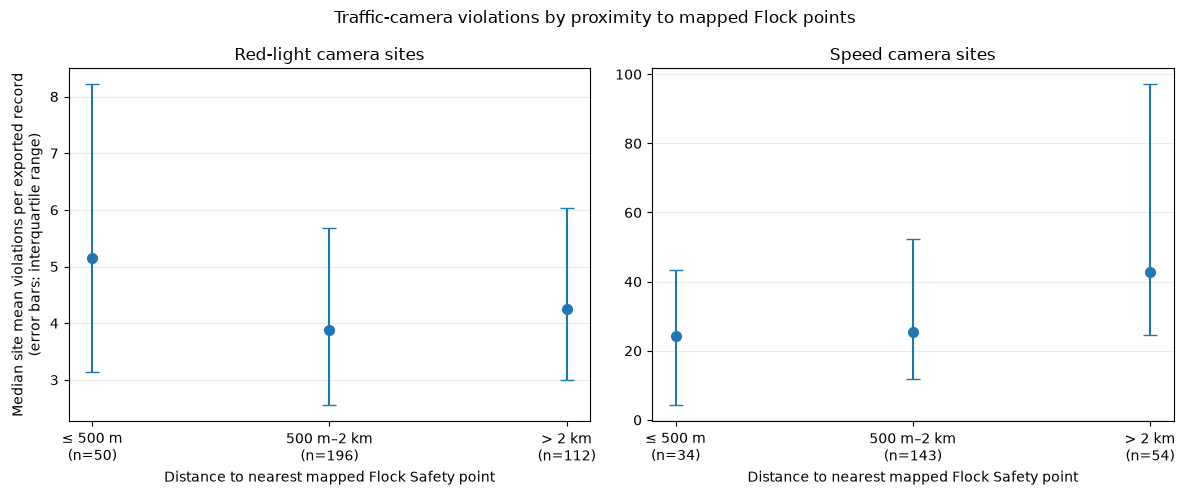

In [4]:
import math

flock_sites = camera_inventory.filter(
    (pl.col("brand") == "Flock Safety")
    & pl.col("latitude").is_between(41.5, 42.1)
    & pl.col("longitude").is_between(-88.0, -87.5)
).select("longitude", "latitude")
flock_coordinates = list(zip(flock_sites["latitude"].to_list(), flock_sites["longitude"].to_list()))

def add_nearest_flock_distance(sites):
    def distance_to_nearest_flock(site_latitude, site_longitude):
        latitude_1 = math.radians(site_latitude)
        longitude_1 = math.radians(site_longitude)
        distances = []
        for flock_latitude, flock_longitude in flock_coordinates:
            latitude_2 = math.radians(flock_latitude)
            longitude_2 = math.radians(flock_longitude)
            delta_latitude = latitude_2 - latitude_1
            delta_longitude = longitude_2 - longitude_1
            haversine = (
                math.sin(delta_latitude / 2) ** 2
                + math.cos(latitude_1) * math.cos(latitude_2)
                * math.sin(delta_longitude / 2) ** 2
            )
            distances.append(2 * 6371 * math.asin(math.sqrt(min(1.0, haversine))))
        return min(distances)

    nearest_distances = [
        distance_to_nearest_flock(latitude, longitude)
        for latitude, longitude in zip(sites["latitude"].to_list(), sites["longitude"].to_list())
    ]
    return sites.with_columns(pl.Series("nearest_flock_km", nearest_distances))

proximity_labels = ["≤ 500 m", "500 m–2 km", "> 2 km"]
traffic_site_results = {}

for name, filename in [
    ("Red-light", "../red_light_100000.csv"),
    ("Speed", "../speed_violations_150000.csv"),
]:
    raw = pl.read_csv(filename, schema_overrides={"VIOLATIONS": pl.String})
    parsed = raw.with_columns(
        pl.col("LATITUDE").cast(pl.Float64, strict=False).alias("latitude"),
        pl.col("LONGITUDE").cast(pl.Float64, strict=False).alias("longitude"),
        pl.col("VIOLATIONS")
        .str.replace_all(",", "")
        .cast(pl.Float64, strict=False)
        .alias("violations"),
    )
    coordinate_rows = parsed.filter(
        pl.col("latitude").is_not_null() & pl.col("longitude").is_not_null()
    ).height
    print(f"{name}: coordinates present for {coordinate_rows:,} of {raw.height:,} records")
    chicago_records = parsed.filter(
        pl.col("latitude").is_between(41.5, 42.1)
        & pl.col("longitude").is_between(-88.0, -87.5)
        & pl.col("violations").is_not_null()
    )
    sites = (
        chicago_records.group_by("CAMERA ID")
        .agg(
            pl.col("latitude").mean(),
            pl.col("longitude").mean(),
            pl.col("violations").mean().alias("site_mean_violations"),
            pl.len().alias("records"),
        )
        .filter(pl.col("latitude").is_not_null() & pl.col("longitude").is_not_null())
    )
    sites = add_nearest_flock_distance(sites).with_columns(
        pl.when(pl.col("nearest_flock_km") <= 0.5)
        .then(pl.lit("≤ 500 m"))
        .when(pl.col("nearest_flock_km") <= 2)
        .then(pl.lit("500 m–2 km"))
        .otherwise(pl.lit("> 2 km"))
        .alias("proximity")
    )
    traffic_site_results[name] = sites
    summary = (
        sites.group_by("proximity")
        .agg(
            pl.len().alias("traffic_camera_sites"),
            pl.col("records").sum().alias("exported_records"),
            pl.col("site_mean_violations").median().alias("median_site_mean"),
        )
        .sort("proximity")
    )
    print(f"{name} camera-site comparison:")
    print(summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, name in zip(axes, ["Red-light", "Speed"]):
    sites = traffic_site_results[name]
    medians, lower_errors, upper_errors, labels = [], [], [], []
    for category in proximity_labels:
        group = sites.filter(pl.col("proximity") == category)["site_mean_violations"]
        if group.len() == 0:
            continue
        q1, median, q3 = group.quantile(0.25), group.median(), group.quantile(0.75)
        medians.append(median)
        lower_errors.append(median - q1)
        upper_errors.append(q3 - median)
        labels.append(f"{category}\n(n={group.len()})")
    ax.errorbar(
        range(len(medians)),
        medians,
        yerr=[lower_errors, upper_errors],
        fmt="o",
        capsize=5,
        markersize=7,
    )
    ax.set_xticks(range(len(labels)), labels)
    ax.set_title(f"{name} camera sites")
    ax.set_xlabel("Distance to nearest mapped Flock Safety point")
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("Median site mean violations per exported record\n(error bars: interquartile range)")
fig.suptitle("Traffic-camera violations by proximity to mapped Flock points")
fig.tight_layout()
plt.show()

## Observations

The graphs compare reported violations from red-light and speed cameras by their distance to a mapped Flock camera; they do **not** count violations recorded by Flock cameras. For red-light cameras, sites within 500 m have a slightly higher median site-level mean number of violations per exported record than sites more than 2 km away. The pattern is reversed for speed cameras: sites more than 2 km away have a higher median site-level mean than nearby sites. These are descriptive differences, not evidence that Flock cameras caused a change in violations.

## Next Steps

**What next?** It would have been convenient if there was a way to count violations recorded by the Flock cameras, but I've yet to figure out that method. So, the next step could be to do exactly that, and compare results with violations recorded by red-light and speed cameras. 
